In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path


In [2]:
# load datasest
df =pd.read_excel(r"C:\\project file\\HDFC-Style Banking Transactions Analysis & Data Cleaning Dashboard (2026)\\Simulated_HDFC_Style_Bank_Transactions_50000_Jan01_Oct10_2026.xlsx")

In [3]:
# disply five rows of the dataset
df.head()

,transaction_id,transaction_datetime,transaction_date,customer_id,account_type,transaction_type,channel,direction,amount_inr,merchant_category,city,status,is_simulated_data
0,SIMTXN0005729,2026-01-01 00:00:15,2026-01-01,106858,Savings,NEFT,Internet Banking,Debit,81767.13,Not Applicable,Indore,Successful,True
1,SIMTXN0032539,2026-01-01 00:13:07,2026-01-01,102488,Savings,POS Purchase,POS,Debit,1496.50,Entertainment,Hyderabad,Successful,True
2,SIMTXN0031954,2026-01-01 00:20:35,2026-01-01,107396,Savings,UPI,Mobile App,Debit,8168.41,Other,Chennai,Successful,True
3,SIMTXN0005494,2026-01-01 00:26:43,2026-01-01,104882,Savings,POS Purchase,POS,Debit,813.81,Shopping,Indore,Successful,True
4,SIMTXN0034553,2026-01-01 00:29:26,2026-01-01,105712,Savings,Bill Payment,Internet Banking,Debit,2251.59,Internet,Mumbai,Successful,True


In [4]:
#check number of rows and columns in the dataset
df.shape

(50000, 13)

In [5]:
#check number of rows and columns in the dataset
df.shape

(50000, 13)

In [6]:
#check missing values in the dataset
df.isnull().sum()

transaction_id          0
transaction_datetime    0
transaction_date        0
customer_id             0
account_type            0
transaction_type        0
channel                 0
direction               0
amount_inr              0
merchant_category       0
city                    0
status                  0
is_simulated_data       0
dtype: int64

In [7]:
#check duplicate values in the dataset
df.duplicated().sum()

np.int64(0)

In [8]:
# standerdize column names in the dataset
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(r"\s+", "_", regex=True)
)

In [9]:
# count the number of unique values in each column
df.nunique()

transaction_id          50000
transaction_datetime    49952
transaction_date          283
customer_id              7991
account_type                2
transaction_type            9
channel                     6
direction                   2
amount_inr              41390
merchant_category          17
city                       10
status                      3
is_simulated_data           1
dtype: int64

In [10]:
# Convert date and amount columns
df["transaction_date"] = pd.to_datetime(
    df["transaction_date"], errors="coerce"
)
df["amount_inr"] = pd.to_numeric(
    df["amount_inr"], errors="coerce"
)

In [11]:
# Remove duplicate transaction IDs
df.drop_duplicates(subset="transaction_id", inplace=True)

In [12]:
# Remove rows with essential missing values
essential_columns = ["transaction_id", "transaction_date", "amount_inr"]

In [13]:
# Remove invalid negative amounts for this example
df = df[df["amount_inr"] >= 0]

In [14]:
# Standardize text fields
for col in [
    "transaction_type",
    "status",
    "account_type",
    "payment_mode",
    "branch"
]:
    for col in ["transaction_type", "status", "account_type", "payment_mode", "branch"]:
        if col in df.columns:
            df[col] = df[col].astype("string").str.strip().str.title()


In [15]:
# Fill missing optional categories
for col in ["transaction_type", "status", "account_type", "payment_mode", "branch"]:
    if col in df.columns:
        df[col] = df[col].fillna("Not Specified")

In [5]:
import pandas as pd

# Keep the requested 2026 date 
# Keep the requested 2026 date 

if "df" not in globals():
    df = pd.read_excel(
        r"C:\project file\HDFC-Style Banking Transactions Analysis & Data Cleaning Dashboard (2026)\Simulated_HDFC_Style_Bank_Transactions_50000_Jan01_Oct10_2026.xlsx"
    )

df = df.loc[
    (df["transaction_date"] >= pd.Timestamp("2026-01-01"))
    & (df["transaction_date"] < pd.Timestamp("2026-10-11"))
].copy()

In [7]:
from pathlib import Path

# Create output folder
output_folder = Path(r"C:\project file\HDFC-Style Banking Transactions Analysis & Data Cleaning Dashboard (2026)\output")
output_folder.mkdir(parents=True, exist_ok=True)

In [8]:
# Save cleaned CSV
df.to_csv("cleaned_transactions.csv", index=False)

In [9]:
# Identify successful transactions
successful_transactions = df[df['status'] == 'success']

In [10]:
# Calculate KPIs
total_transactions = len(df)
successful = df[df["status"].str.lower() == "successful"].copy()
successful_transactions = successful.copy()
successful_count = len(successful)

failed_count = df["status"].str.lower().isin(
    ["failed", "failure", "declined"]
).sum()

total_value = successful["amount_inr"].sum()
average_value = successful["amount_inr"].mean()
average_value = successful["amount_inr"].mean()
unique_customers = df["customer_id"].nunique()

success_rate = (
    successful_count / total_transactions * 100
    if total_transactions else 0
)

print("\n--- Banking KPI Report ---")
print("Total Transactions:", total_transactions)
print("Successful Transactions:", successful_count)
print("Failed Transactions:", failed_count)
print("Unique Customers:", unique_customers)
print("Successful Transaction Value:", round(total_value, 2))
print("Average Transaction Value:", round(average_value, 2))
print("Success Rate:", round(success_rate, 2), "%")


--- Banking KPI Report ---
Total Transactions: 50000
Successful Transactions: 44050
Failed Transactions: 3502
Unique Customers: 7991
Successful Transaction Value: 133860421.35
Average Transaction Value: 3038.83
Success Rate: 88.1 %


In [30]:

monthly = (
    successful.groupby(
        successful["transaction_date"].dt.to_period("M")
    )
    .agg(
        transaction_count=("transaction_id", "count"),
        total_amount=("amount_inr", "sum")
    )
    .reset_index()
    .rename(columns={"transaction_date": "month"})
)

monthly["month"] = monthly["month"].astype(str)
output_folder.mkdir(parents=True, exist_ok=True)
monthly.to_csv(
    "output/monthly_analysis.csv", index=False
)

print(monthly)


     month  transaction_count  total_amount
0  2026-01               4747   13651810.86
1  2026-02               4400   13911324.80
2  2026-03               4840   14955648.34
3  2026-04               4568   13391840.29
4  2026-05               4769   14592150.36
5  2026-06               4784   15519684.82
6  2026-07               4775   14305280.11
7  2026-08               4900   14207240.51
8  2026-09               4730   14417168.85
9  2026-10               1537    4908272.41


In [ ]:
import pandas as pd

import matplotlib.pyplot as plt
plt.figure(figsize=(12, 6))

if "monthly" not in globals():
    if "df" not in globals():
        df = pd.read_excel(
            r"C:\project file\HDFC-Style Banking Transactions Analysis & Data Cleaning Dashboard (2026)\Simulated_HDFC_Style_Bank_Transactions_50000_Jan01_Oct10_2026.xlsx"
        )
        df.columns = (
            df.columns.str.strip()
            .str.lower()
            .str.replace(r"\s+", "_", regex=True)
        )
        df["transaction_date"] = pd.to_datetime(
            df["transaction_date"], errors="coerce"
        )

    successful = df[
        df["status"].astype("string").str.strip().str.lower().isin(
            ["success", "successful"]
        )
    ].copy()

    monthly = (
        successful.groupby(
            successful["transaction_date"].dt.to_period("M")
        )
        .agg(total_amount=("amount_inr", "sum"))
        .reset_index()
        .rename(columns={"transaction_date": "month"})
    )
    monthly["month"] = monthly["month"].astype(str)

plt.plot(
    pd.to_datetime(monthly["month"], format="%Y-%m"),
    monthly["total_amount"],
    marker="o"
)

plt.title("Monthly Banking Transaction Analysis - 2026")
plt.xlabel("Month")
plt.ylabel("Successful Transaction Value")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    "output/monthly_transaction_trend.png",
    dpi=150
)

plt.show()


NameError: name 'df' is not defined

<Figure size 1200x600 with 0 Axes>

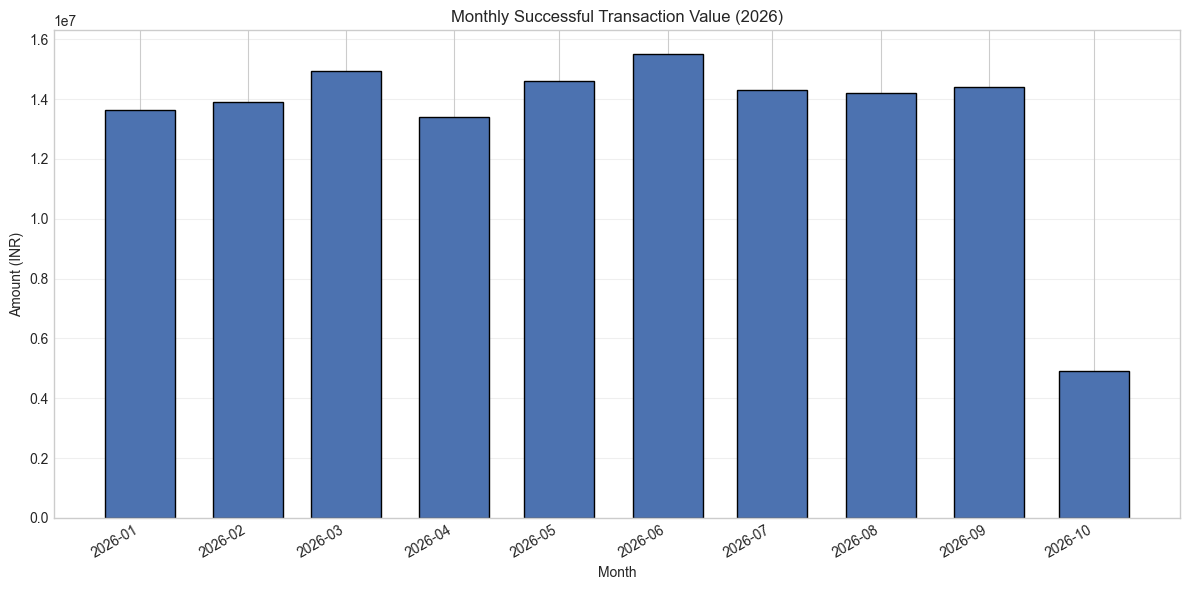

In [14]:
import matplotlib.pyplot as plt
plt.style.use("seaborn-v0_8-whitegrid")

# Ensure the monthly summary exists before using it
if "monthly" not in globals():
       successful = df[df["status"].str.lower() == "successful"].copy()
       monthly = (
              successful.groupby(successful["transaction_date"].dt.to_period("M"))
              .agg(
                     transaction_count=("transaction_id", "count"),
                     total_amount=("amount_inr", "sum")
              )
              .reset_index()
              .rename(columns={"transaction_date": "month"})
       )
       monthly["month"] = monthly["month"].astype(str)

months = pd.to_datetime(monthly["month"], format="%Y-%m")
fig, ax = plt.subplots(figsize=(12, 6))

ax.bar(
       months,
       monthly["total_amount"],
       color="#4C72B0",
       edgecolor="black",
       width=20
)

ax.set_title("Monthly Successful Transaction Value (2026)")
ax.set_xlabel("Month")
ax.set_ylabel("Amount (INR)")
ax.grid(axis="y", alpha=0.3)
fig.autofmt_xdate()
plt.tight_layout()

plt.savefig(output_folder / "monthly_transaction_value_bar.png", dpi=150)
plt.show()

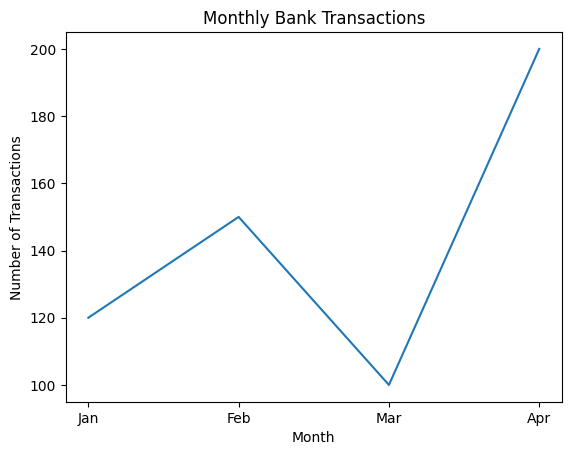

In [1]:
import matplotlib.pyplot as plt

months = ["Jan", "Feb", "Mar", "Apr"]
transactions = [120, 150, 100, 200]

plt.plot(months, transactions)
plt.title("Monthly Bank Transactions")
plt.xlabel("Month")
plt.ylabel("Number of Transactions")
plt.show()

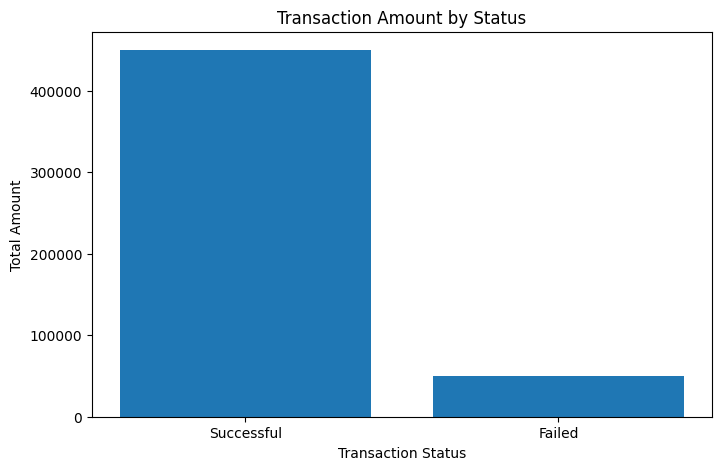

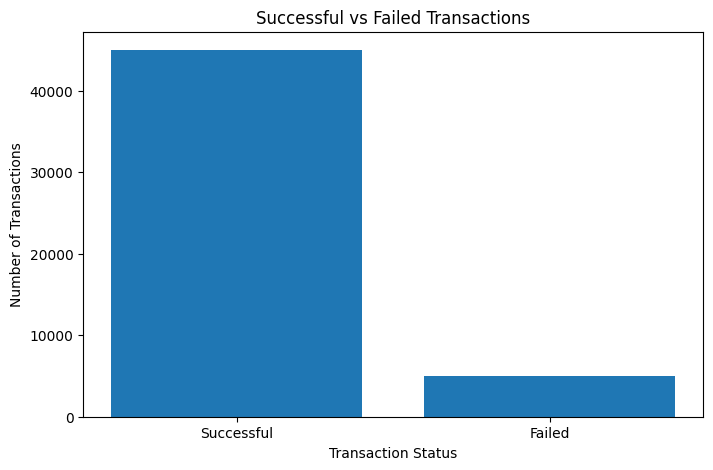

In [2]:
plt.figure(figsize=(8, 5))
plt.bar(["Successful", "Failed"], [450000, 50000])
plt.title("Transaction Amount by Status")
plt.xlabel("Transaction Status")
plt.ylabel("Total Amount")
plt.show()

# Successful vs Failed Transactions
plt.figure(figsize=(8, 5))
plt.bar(["Successful", "Failed"], [45000, 5000])
plt.title("Successful vs Failed Transactions")
plt.xlabel("Transaction Status")
plt.ylabel("Number of Transactions")
plt.show()

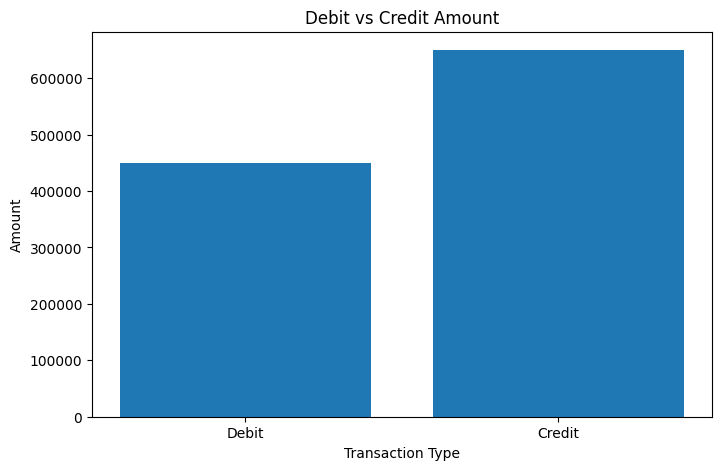

In [5]:
# Debit vs Credit Amount
plt.figure(figsize=(8, 5))
plt.bar(["Debit", "Credit"], [450000, 650000])
plt.title("Debit vs Credit Amount")
plt.xlabel("Transaction Type")
plt.ylabel("Amount")
plt.show()



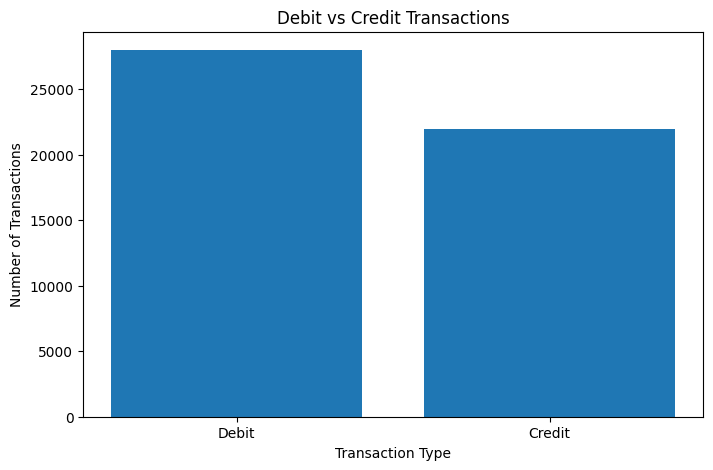

In [4]:
# Debit vs Credit Transactions Count
plt.figure(figsize=(8, 5))
plt.bar(["Debit", "Credit"], [28000, 22000])
plt.title("Debit vs Credit Transactions")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Transactions")
plt.show()